# Assistant Data Analyst E-commerce (RAG + Text-to-SQL)
### *Par Simon Ritz, Guy Béni Ntwari et Aimable Iradukunda*

Assistant conversationnel qui répond en langage naturel à des questions métier sur une base e-commerce (Olist, SQLite) en générant puis en exécutant des requêtes SQL. Un système RAG (embeddings + FAISS) retrouve des exemples question/SQL proches pour guider le LLM (Mistral).

**Instructions :**
1. Ajouter la clé API Mistral : secret Colab `MISTRAL_API_KEY`, ou variable d'environnement `MISTRAL_API_KEY` en local (sinon elle est demandée en saisie masquée)
2. Exécuter les cellules dans l'ordre (les embeddings sont recalculés puis sauvegardés dans `faiss_index.bin` et `qa_pairs.pkl`)
3. Utiliser `talk_to_assistant("votre question")` pour discuter avec l'assistant

*Plan gratuit Mistral : le débit est limité, un ralentisseur automatique est inclus (voir la cellule « Limitation de débit »).*


In [ ]:
!pip install -q kagglehub sentence-transformers faiss-cpu mistralai matplotlib pandas

# 1. Chargement des données

In [ ]:
import kagglehub

path = kagglehub.dataset_download("terencicp/e-commerce-dataset-by-olist-as-an-sqlite-database")
print("Path to dataset files:", path)

100%|██████████| 48.7M/48.7M [00:00<00:00, 126MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/terencicp/e-commerce-dataset-by-olist-as-an-sqlite-database/versions/1


In [ ]:
import sqlite3
import os
import shutil
import pandas as pd

# Trouver le fichier .sqlite
db_file = [f for f in os.listdir(path) if f.endswith('.sqlite') or f.endswith('.db')][0]
db_path_source = os.path.join(path, db_file)
WORKDIR = '/content' if os.path.isdir('/content') else os.getcwd()   # Colab ou local
db_path_writable = os.path.join(WORKDIR, db_file)

shutil.copyfile(db_path_source, db_path_writable)
print("Base de données copiée :", db_path_writable)

conn = sqlite3.connect(db_path_writable)
cursor = conn.cursor()

# Renommer les tables pour correspondre au sujet
rename_map = {
    'order_items': 'items',
    'order_payments': 'payments'
}

cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
existing_tables = [t[0] for t in cursor.fetchall()]

for old_name, new_name in rename_map.items():
    if old_name in existing_tables and new_name not in existing_tables:
        cursor.execute(f"ALTER TABLE {old_name} RENAME TO {new_name};")
        print(f" {old_name} → {new_name}")

conn.commit()

cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = [t[0] for t in cursor.fetchall()]
print("\nTables disponibles :", tables)

Base de données copiée : /content/olist.sqlite
 order_items → items
 order_payments → payments

Tables disponibles : ['product_category_name_translation', 'sellers', 'customers', 'geolocation', 'items', 'payments', 'order_reviews', 'orders', 'products', 'leads_qualified', 'leads_closed']


# Aperçu des données

In [ ]:
ALLOWED_TABLES = ['customers', 'items', 'orders', 'payments', 'products']

for table in ALLOWED_TABLES:
    if table in tables:
        cursor.execute(f"PRAGMA table_info({table});")
        columns = cursor.fetchall()
        print(f"\n=== {table.upper()} ===")
        for col in columns:
            print(f"  {col[1]:30s} | {col[2]:15s} | PK={col[5]}")
    else:
        print(f"\n Table '{table}' non trouvée")


=== CUSTOMERS ===
  customer_id                    | TEXT            | PK=0
  customer_unique_id             | TEXT            | PK=0
  customer_zip_code_prefix       | INTEGER         | PK=0
  customer_city                  | TEXT            | PK=0
  customer_state                 | TEXT            | PK=0

=== ITEMS ===
  order_id                       | TEXT            | PK=0
  order_item_id                  | INTEGER         | PK=0
  product_id                     | TEXT            | PK=0
  seller_id                      | TEXT            | PK=0
  shipping_limit_date            | TEXT            | PK=0
  price                          | REAL            | PK=0
  freight_value                  | REAL            | PK=0

=== ORDERS ===
  order_id                       | TEXT            | PK=0
  customer_id                    | TEXT            | PK=0
  order_status                   | TEXT            | PK=0
  order_purchase_timestamp       | TEXT            | PK=0
  order_approved_at   

In [ ]:
for table in ALLOWED_TABLES:
    if table in tables:
        df = pd.read_sql_query(f"SELECT * FROM {table}", conn)
        display(df.head())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


# 2. Prompt Engineering — Schéma + Exemples RAG

In [ ]:
def generer_schema(conn, tables):
    """Génère le schéma des tables avec les vrais types SQL (via PRAGMA)"""
    schema = ""
    cursor_local = conn.cursor()
    for table in tables:
        cursor_local.execute(f"PRAGMA table_info({table});")
        columns = cursor_local.fetchall()
        schema += f"\n**{table}**\n"
        for col in columns:
            col_name = col[1]
            col_type = col[2] if col[2] else "TEXT"
            pk = " (PK)" if col[5] else ""
            schema += f"- {col_name} ({col_type}){pk}\n"
    return schema

SCHEMA_TABLES = generer_schema(conn, ALLOWED_TABLES)

# SYSTEM_PROMPT

In [ ]:
SYSTEM_PROMPT = """Tu es un assistant data analyst spécialisé dans l'analyse d'une base de données e-commerce brésilienne (Olist).

Tu as accès à 5 tables dans une base SQLite :

### Tables et colonnes ###
{schema}

### Relations (clés étrangères) ###
- orders.customer_id → customers.customer_id
- items.order_id → orders.order_id
- items.product_id → products.product_id
- payments.order_id → orders.order_id

### Règles ###
1. Génère UNIQUEMENT la requête SQL, sans explication ni commentaire.
2. Utilise la syntaxe SQLite (strftime pour les dates, pas DATE_FORMAT).
3. Pour les revenus/chiffre d'affaires, utilise payments.payment_value avec order_status = 'delivered'.
4. Pour le prix des produits, utilise items.price.
5. Pour le panier moyen, fais la somme par order_id puis la moyenne.
6. Une commande peut avoir plusieurs articles (items) et plusieurs paiements (payments).
7. Les catégories de produits sont en portugais (ex: beleza_saude, informatica_acessorios).
8. Ne réponds qu'aux questions liées à l'analyse de cette base e-commerce.

CONTEXTE CRITIQUE :
- Seules les tables fournies ci-dessus existent.
- Les noms de tables et de colonnes fournis sont la SEULE source de vérité.
""".format(schema=SCHEMA_TABLES)


# Paires question/SQL (RAG)

In [ ]:
qa_pairs = [
    # ===== REVENUS =====
    {
        "question": "Quels sont les revenus mensuels et leur évolution au fil du temps ?",
        "sql": """SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS mois,
       ROUND(SUM(p.payment_value), 2) AS revenu_mensuel
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
GROUP BY mois ORDER BY mois;"""
    },
    {
        "question": "Quel est le revenu total pour l'année 2017 ?",
        "sql": """SELECT ROUND(SUM(p.payment_value), 2) AS revenu_total
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
  AND strftime('%Y', o.order_purchase_timestamp) = '2017';"""
    },
    {
        "question": "Combien a-t-on gagné par trimestre ?",
        "sql": """SELECT strftime('%Y', o.order_purchase_timestamp) AS annee,
       CASE
           WHEN CAST(strftime('%m', o.order_purchase_timestamp) AS INTEGER) BETWEEN 1 AND 3 THEN 'T1'
           WHEN CAST(strftime('%m', o.order_purchase_timestamp) AS INTEGER) BETWEEN 4 AND 6 THEN 'T2'
           WHEN CAST(strftime('%m', o.order_purchase_timestamp) AS INTEGER) BETWEEN 7 AND 9 THEN 'T3'
           ELSE 'T4'
       END AS trimestre,
       ROUND(SUM(p.payment_value), 2) AS revenu
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
GROUP BY annee, trimestre ORDER BY annee, trimestre;"""
    },
    {
        "question": "Quel est le chiffre d'affaires total ?",
        "sql": """SELECT ROUND(SUM(p.payment_value), 2) AS chiffre_affaires
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered';"""
    },
    {
        "question": "Quel est le revenu par état du client ?",
        "sql": """SELECT c.customer_state, ROUND(SUM(p.payment_value), 2) AS revenu
FROM orders o
JOIN payments p ON o.order_id = p.order_id
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state ORDER BY revenu DESC;"""
    },
    {
        "question": "Quel est le revenu mensuel pour l'année 2018 ?",
        "sql": """SELECT strftime('%m', o.order_purchase_timestamp) AS mois,
       ROUND(SUM(p.payment_value), 2) AS revenu_mensuel
FROM orders o
JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
  AND strftime('%Y', o.order_purchase_timestamp) = '2018'
GROUP BY mois ORDER BY mois;"""
    },

    # ===== PRODUITS =====
    {
        "question": "Quels sont les 10 produits les plus vendus en volume ?",
        "sql": """SELECT pr.product_category_name, COUNT(*) AS nb_ventes
FROM items i
JOIN products pr ON i.product_id = pr.product_id
GROUP BY pr.product_category_name
ORDER BY nb_ventes DESC LIMIT 10;"""
    },
    {
        "question": "Quels sont les 10 produits les plus vendus en valeur ?",
        "sql": """SELECT pr.product_category_name, ROUND(SUM(i.price), 2) AS valeur_totale
FROM items i
JOIN products pr ON i.product_id = pr.product_id
GROUP BY pr.product_category_name
ORDER BY valeur_totale DESC LIMIT 10;"""
    },
    {
        "question": "Combien de produits différents ont été vendus ?",
        "sql": """SELECT COUNT(DISTINCT product_id) AS nb_produits FROM items;"""
    },
    {
        "question": "Quelles sont les catégories de produits disponibles ?",
        "sql": """SELECT DISTINCT product_category_name FROM products WHERE product_category_name IS NOT NULL ORDER BY product_category_name;"""
    },
    {
        "question": "Quel est le prix moyen par catégorie de produit ?",
        "sql": """SELECT pr.product_category_name, ROUND(AVG(i.price), 2) AS prix_moyen
FROM items i
JOIN products pr ON i.product_id = pr.product_id
GROUP BY pr.product_category_name
ORDER BY prix_moyen DESC;"""
    },

    # ===== PANIER MOYEN =====
    {
        "question": "Quel est le panier moyen global ?",
        "sql": """SELECT ROUND(AVG(total), 2) AS panier_moyen
FROM (
    SELECT o.order_id, SUM(p.payment_value) AS total
    FROM orders o
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id
);"""
    },
    {
        "question": "Quel est le panier moyen pour la catégorie beleza_saude ?",
        "sql": """SELECT ROUND(AVG(total), 2) AS panier_moyen
FROM (
    SELECT o.order_id, SUM(i.price + i.freight_value) AS total
    FROM orders o
    JOIN items i ON o.order_id = i.order_id
    JOIN products pr ON i.product_id = pr.product_id
    WHERE pr.product_category_name = 'beleza_saude'
      AND o.order_status = 'delivered'
    GROUP BY o.order_id
);"""
    },
    {
        "question": "Quel est le panier moyen par mois ?",
        "sql": """SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS mois,
       ROUND(AVG(total), 2) AS panier_moyen
FROM (
    SELECT o.order_id, o.order_purchase_timestamp, SUM(p.payment_value) AS total
    FROM orders o
    JOIN payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id
) o
GROUP BY mois ORDER BY mois;"""
    },

    # ===== COMMANDES =====
    {
        "question": "Combien de commandes ont été passées au total ?",
        "sql": """SELECT COUNT(*) AS nb_commandes FROM orders;"""
    },
    {
        "question": "Combien de commandes ont été livrées ?",
        "sql": """SELECT COUNT(*) AS nb_livrees FROM orders WHERE order_status = 'delivered';"""
    },
    {
        "question": "Quelle est la répartition des commandes par statut ?",
        "sql": """SELECT order_status, COUNT(*) AS nb FROM orders GROUP BY order_status ORDER BY nb DESC;"""
    },
    {
        "question": "Combien de commandes par mois ?",
        "sql": """SELECT strftime('%Y-%m', order_purchase_timestamp) AS mois, COUNT(*) AS nb_commandes
FROM orders
GROUP BY mois ORDER BY mois;"""
    },
    {
        "question": "Quel est le nombre moyen d'articles par commande ?",
        "sql": """SELECT ROUND(AVG(nb_articles), 2) AS moy_articles
FROM (
    SELECT order_id, COUNT(*) AS nb_articles FROM items GROUP BY order_id
);"""
    },

    # ===== CLIENTS =====
    {
        "question": "Combien de clients uniques ont passé une commande ?",
        "sql": """SELECT COUNT(DISTINCT customer_unique_id) AS nb_clients
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id;"""
    },
    {
        "question": "Quelles sont les 5 villes avec le plus de commandes ?",
        "sql": """SELECT c.customer_city, COUNT(o.order_id) AS nb_commandes
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.customer_city
ORDER BY nb_commandes DESC LIMIT 5;"""
    },
    {
        "question": "Quels sont les 5 états avec le plus de clients ?",
        "sql": """SELECT customer_state, COUNT(DISTINCT customer_unique_id) AS nb_clients
FROM customers
GROUP BY customer_state
ORDER BY nb_clients DESC LIMIT 5;"""
    },
    {
        "question": "Combien de clients ont commandé plus d'une fois ?",
        "sql": """SELECT COUNT(*) AS clients_recurrents
FROM (
    SELECT customer_unique_id, COUNT(DISTINCT o.order_id) AS nb_commandes
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY customer_unique_id
    HAVING nb_commandes > 1
);"""
    },

    # ===== PAIEMENTS =====
    {
        "question": "Quelle est la répartition des moyens de paiement ?",
        "sql": """SELECT payment_type, COUNT(*) AS nb, ROUND(SUM(payment_value), 2) AS total
FROM payments
GROUP BY payment_type ORDER BY total DESC;"""
    },
    {
        "question": "Quel est le nombre moyen de versements par commande ?",
        "sql": """SELECT ROUND(AVG(payment_installments), 1) AS moy_versements FROM payments;"""
    },
    {
        "question": "Quel est le montant moyen payé par carte de crédit ?",
        "sql": """SELECT ROUND(AVG(payment_value), 2) AS montant_moyen
FROM payments WHERE payment_type = 'credit_card';"""
    },

    # ===== LIVRAISON =====
    {
        "question": "Quel est le délai moyen de livraison en jours ?",
        "sql": """SELECT ROUND(AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)), 1) AS delai_moyen_jours
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL;"""
    },
    {
        "question": "Quel est le délai moyen de livraison par état ?",
        "sql": """SELECT c.customer_state,
       ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 1) AS delai_moyen_jours
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state ORDER BY delai_moyen_jours DESC;"""
    },
    {
        "question": "Combien de commandes ont été livrées en retard ?",
        "sql": """SELECT COUNT(*) AS nb_retards
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date > order_estimated_delivery_date;"""
    },
]

print(f"{len(qa_pairs)} paires question/SQL définies")

29 paires question/SQL définies


# 3. Système RAG — Embeddings + FAISS

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np
import faiss
import pickle

embed_model = SentenceTransformer('all-MiniLM-L6-v2')

questions = [pair["question"] for pair in qa_pairs]
embeddings = embed_model.encode(questions, convert_to_numpy=True)

dimension = embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(embeddings)

print(f" Index FAISS créé : {index.ntotal} vecteurs, dimension {dimension}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

 Index FAISS créé : 29 vecteurs, dimension 384


In [ ]:
faiss.write_index(index, "faiss_index.bin")

with open("qa_pairs.pkl", "wb") as f:
    pickle.dump(qa_pairs, f)

print("Sauvegardé : faiss_index.bin + qa_pairs.pkl")

Sauvegardé : faiss_index.bin + qa_pairs.pkl


In [ ]:
from sentence_transformers import SentenceTransformer
import faiss
import pickle

embed_model = SentenceTransformer('all-MiniLM-L6-v2')

index = faiss.read_index("faiss_index.bin")

with open("qa_pairs.pkl", "rb") as f:
    qa_pairs = pickle.load(f)

print(f"Chargé : {index.ntotal} vecteurs, {len(qa_pairs)} paires")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Chargé : 29 vecteurs, 29 paires


In [ ]:
def rechercher_exemples(question_utilisateur, top_k=3):
    """Recherche les paires question/SQL les plus similaires"""
    query_embedding = embed_model.encode([question_utilisateur], convert_to_numpy=True)
    distances, indices = index.search(query_embedding, top_k)

    resultats = []
    for i, idx in enumerate(indices[0]):
        resultats.append({
            "question": qa_pairs[idx]["question"],
            "sql": qa_pairs[idx]["sql"],
            "distance": float(distances[0][i])
        })
    return resultats


def construire_prompt(question_utilisateur, top_k=3):
    """Construit le prompt enrichi avec les exemples RAG"""
    exemples = rechercher_exemples(question_utilisateur, top_k)

    prompt = "Voici des exemples de questions similaires et leurs requêtes SQL :\n"

    for i, ex in enumerate(exemples, 1):
        prompt += f"\nExemple {i}:"
        prompt += f"\nQuestion : {ex['question']}"
        prompt += f"\nSQL : {ex['sql']}\n"

    prompt += f"\nMaintenant, génère UNIQUEMENT la requête SQL pour cette question :"
    prompt += f"\nQuestion : {question_utilisateur}"
    prompt += f"\nSQL :"

    return prompt

print("Fonctions RAG définies")

Fonctions RAG définies


# 4. Configuration Mistral + Fonctions de l'assistant

In [ ]:
import os
from mistralai.client import Mistral

def charger_cle_api():
    """Secrets Colab -> variable d'environnement -> saisie masquée."""
    try:
        from google.colab import userdata
        return userdata.get("MISTRAL_API_KEY")
    except Exception:
        pass
    cle = os.getenv("MISTRAL_API_KEY")
    if cle:
        return cle
    from getpass import getpass
    return getpass("Clé API Mistral : ")

MISTRAL_API_KEY = charger_cle_api()
client = Mistral(api_key=MISTRAL_API_KEY)
MODEL = "mistral-small-latest"

print("Mistral AI configuré")

Mistral AI configuré


## Limitation de débit (plan gratuit Mistral)
L'assistant enchaîne plusieurs appels par question. Ce wrapper ajoute une pause entre les appels et relance automatiquement en cas d'erreur 429. Avec une clé payante, mettre `PAUSE_ENTRE_APPELS = 0`.

In [ ]:
import time, random

PAUSE_ENTRE_APPELS = 1.2   # secondes (0 avec un plan payant)
_appel_original = client.chat.complete

def _appel_avec_retry(*args, **kwargs):
    for essai in range(6):
        time.sleep(PAUSE_ENTRE_APPELS)
        try:
            return _appel_original(*args, **kwargs)
        except Exception as e:
            if "429" in str(e) and essai < 5:
                attente = 2 ** essai + random.random()
                print(f"Limite de débit atteinte, nouvelle tentative dans {attente:.0f}s...")
                time.sleep(attente)
            else:
                raise

client.chat.complete = _appel_avec_retry
print("Gestion du débit activée")

In [ ]:
def verifier_perimetre(question):
    """Vérifie si la question concerne le périmètre e-commerce"""
    response = client.chat.complete(
        model=MODEL,
        messages=[
            {"role": "system", "content": """Tu es un classificateur. Réponds UNIQUEMENT par "OUI" ou "NON".
La question peut-elle être traitée par un assistant qui analyse une base de données e-commerce contenant des tables sur les clients, commandes, produits, paiements et livraisons ?

Exemples de OUI :
- "Quels sont les revenus mensuels ?" → OUI
- "Y a des clients fidèles ?" → OUI
- "C'est quoi les données que t'as ?" → OUI
- "T'as des infos sur 2016 ?" → OUI
- "Les brésiliens achètent quoi ?" → OUI
- "Quel est le produit le moins cher ?" → OUI
- "Qui dépense le plus ?" → OUI
- "Combien de commandes par mois ?" → OUI
- "Quelles années sont disponibles ?" → OUI

Exemples de NON :
- "Comment faire une pâte à crêpe ?" → NON
- "Quelle est la distance entre Lille et Paris ?" → NON
- "Quel est le meilleur produit pour les cheveux ?" → NON
- "Comment augmenter mes revenus en freelance ?" → NON
- "Livre-moi une pizza" → NON
- "Bonjour" → NON
- "Raconte-moi une blague" → NON"""},
            {"role": "user", "content": question}
        ],
        max_tokens=3,
        temperature=0
    )
    reponse = response.choices[0].message.content.strip().upper()
    return "OUI" in reponse

def reformuler_question(question, history):
    if not history:
        return question

    messages = [
        {"role": "system", "content": """Tu reformules les questions ambiguës en questions complètes et autonomes.
Si la question fait référence à un échange précédent ("et pour 2018 ?", "et par ville ?"), reformule-la en intégrant le contexte.
Si elle est déjà complète, renvoie-la telle quelle.

RÈGLES STRICTES :
- Réponds UNIQUEMENT avec la question reformulée, rien d'autre.
- Pas de markdown, pas de gras, pas de titres, pas de commentaires.
- Juste la question en texte brut."""}
    ]

    for entry in history[-4:]:
        messages.append({"role": "user", "content": entry["question"]})
        if "response" in entry:
            messages.append({"role": "assistant", "content": entry["response"][:300]})

    messages.append({"role": "user", "content": f"Reformule cette question : {question}"})

    response = client.chat.complete(
        model=MODEL,
        messages=messages,
        max_tokens=150,
        temperature=0
    )
    return response.choices[0].message.content.strip().strip("#*").strip()


def generer_sql(prompt):
    """Génère une requête SQL à partir du prompt enrichi"""
    response = client.chat.complete(
        model=MODEL,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": prompt}
        ],
        max_tokens=500,
        temperature=0
    )
    sql = response.choices[0].message.content.strip()
    # Nettoyer les balises markdown si présentes
    sql = sql.replace("```sql", "").replace("```", "").strip()
    return sql


def executer_sql(sql):
    """Exécute une requête SQL et retourne colonnes, lignes, erreur"""
    try:
        cursor.execute(sql)
        columns = [desc[0] for desc in cursor.description]
        rows = cursor.fetchall()
        return columns, rows, None
    except Exception as e:
        return None, None, str(e)


def formater_reponse(question, sql, columns, rows):
    """Formate les résultats SQL en réponse lisible via Mistral"""
    if len(rows) > 20:
        apercu = rows[:20]
        note = f"\n(... {len(rows)} lignes au total, 20 premières affichées)"
    else:
        apercu = rows
        note = ""

    resultats_str = f"Colonnes : {columns}\nDonnées : {apercu}{note}"

    response = client.chat.complete(
        model=MODEL,
        messages=[
            {"role": "system", "content": """Tu es un assistant data analyst. Présente les résultats SQL de manière claire et lisible en français.

RÈGLES DE FORMAT :
- Présente les données dans un tableau lisible.
- Ajoute 2-3 observations courtes maximum (une ligne chacune).
- Pas de recommandations, pas de "prochaines étapes", pas de suggestions.
- Pas de blocs "Conclusion", "Recommandations", "Pour approfondir".
- Sois concis et direct."""},
            {"role": "user", "content": f"Question : {question}\nSQL : {sql}\nRésultats : {resultats_str}"}
        ],
        max_tokens=800,
        temperature=0.3
    )
    return response.choices[0].message.content.strip()


def verifier_securite(question):
    """Bloque les commandes destructrices, injections SQL et questions discriminatoires"""
    q = question.strip().upper()

    # Blocage des mots destructeurs
    mots_interdits = ["SUPPRIME", "EFFACE", "DELETE", "DROP", "TRUNCATE",
                      "UPDATE", "INSERT", "ALTER", "DETRUIT", "VIDE"]
    for mot in mots_interdits:
        if mot in q:
            return False, "destructif"

    # Blocage des requêtes SQL brutes
    if q.startswith("SELECT") or q.startswith("DROP") or q.startswith("DELETE"):
        return False, "sql"

    # Blocage des questions discriminatoires
    mots_discriminatoires = ["NOIR", "NOIRS", "BLANC", "BLANCS", "ARABE",
                             "ARABES", "ASIATIQUE", "ASIATIQUES", "JUIF",
                             "JUIFS", "MUSULMAN", "MUSULMANS", "RACE",
                             "ETHNIE", "RELIGION", "SEXE", "GENRE",
                             "HOMOSEXUEL", "GAY", "LESBIENNE", "TRANS",
                             "HANDICAPÉ", "HANDICAPÉS", "IMMIGRÉ", "IMMIGRÉS"]
    for mot in mots_discriminatoires:
        if mot in q:
            return False, "discriminatoire"

    return True, "ok"

print("Fonctions définies")

Fonctions définies


In [ ]:
import matplotlib.pyplot as plt
import json

def choisir_graphique(question, columns, rows):
    """Demande à Mistral quel type de graphique est adapté"""
    if len(rows) < 2 or len(columns) < 2:
        return None

    apercu = rows[:10]

    response = client.chat.complete(
        model=MODEL,
        messages=[
            {"role": "system", "content": """Tu es un expert en data visualisation.
On te donne une question, des colonnes et un aperçu des données SQL.
Réponds UNIQUEMENT avec un JSON valide (sans markdown, sans backticks) :
{
  "type": "bar" | "barh" | "line" | "pie" | "none",
  "x": "nom_colonne_x",
  "y": "nom_colonne_y",
  "titre": "Titre du graphique"
}

Règles :
- "line" pour des évolutions temporelles (mois, années, trimestres).
- "bar" pour des classements ou comparaisons (top N, par catégorie) avec peu de catégories.
- "barh" pour des classements avec beaucoup de catégories ou des noms longs.
- "pie" pour des répartitions en pourcentage (max 6-7 parts).
- "none" si les données ne se prêtent pas à un graphique (1 seule ligne, données textuelles pures).
- x = la colonne des labels/catégories/dates.
- y = la colonne numérique à représenter.
"""},
            {"role": "user", "content": f"Question : {question}\nColonnes : {columns}\nDonnées : {apercu}"}
        ],
        max_tokens=150,
        temperature=0
    )
    try:
        raw = response.choices[0].message.content.strip()
        raw = raw.replace("```json", "").replace("```", "").strip()
        config = json.loads(raw)
        if config.get("type") == "none":
            return None
        return config
    except:
        return None


def generer_graphique(question, columns, rows):
    """Génère un graphique matplotlib adapté aux résultats"""
    config = choisir_graphique(question, columns, rows)
    if config is None:
        return

    df = pd.DataFrame(rows, columns=columns)
    x_col = config["x"]
    y_col = config["y"]
    chart_type = config["type"]
    titre = config.get("titre", "Résultat")

    if x_col not in df.columns or y_col not in df.columns:
        return

    df_plot = df.head(20).copy()
    df_plot[y_col] = pd.to_numeric(df_plot[y_col], errors='coerce')
    df_plot = df_plot.dropna(subset=[y_col])

    if df_plot.empty:
        return

    palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974", "#64B5CD"]
    fig, ax = plt.subplots(figsize=(10, 5))

    if chart_type == "pie":
        # Regrouper les petites parts (< 3%) dans "Autres"
        total = df_plot[y_col].sum()
        df_plot["pct"] = df_plot[y_col] / total * 100
        mask = df_plot["pct"] < 3
        if mask.any():
            autres = pd.DataFrame({
                x_col: ["Autres"],
                y_col: [df_plot.loc[mask, y_col].sum()],
                "pct": [df_plot.loc[mask, "pct"].sum()]
            })
            df_plot = pd.concat([df_plot[~mask], autres], ignore_index=True)

        wedges, texts, autotexts = ax.pie(
            df_plot[y_col],
            labels=df_plot[x_col].astype(str),
            autopct='%1.1f%%',
            startangle=90,
            colors=palette[:len(df_plot)],
            pctdistance=0.75,
            labeldistance=1.15
        )
        for t in texts:
            t.set_fontsize(10)
        for t in autotexts:
            t.set_fontsize(9)
            t.set_fontweight('bold')

    elif chart_type == "bar":
        ax.bar(df_plot[x_col].astype(str), df_plot[y_col], color=palette[0])
        plt.xticks(rotation=45, ha='right')
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)

    elif chart_type == "barh":
        df_plot = df_plot.sort_values(y_col, ascending=True)
        ax.barh(df_plot[x_col].astype(str), df_plot[y_col], color=palette[0])
        ax.set_xlabel(y_col)
        ax.set_ylabel(x_col)

    elif chart_type == "line":
        ax.plot(df_plot[x_col].astype(str), df_plot[y_col], marker='o', color=palette[0], linewidth=2)
        ax.fill_between(range(len(df_plot)), df_plot[y_col], alpha=0.15, color=palette[0])
        plt.xticks(rotation=45, ha='right')
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)

    ax.set_title(titre, fontsize=13, fontweight='bold', pad=15)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

print("Fonction de graphique définie")

Fonction de graphique définie


# 5. Fonction principale — `talk_to_assistant`

In [ ]:
from IPython.display import display, Markdown

conversation_history = []

def talk_to_assistant(question):
    global conversation_history

    # SÉCURITÉ
    if not question.strip():
        reponse = "Veuillez poser une question."
        print(reponse)
        return {"question": question, "sql": None, "response": reponse}

    securite_ok, raison = verifier_securite(question)
    if not securite_ok:
        if raison == "discriminatoire":
            reponse = ("Je ne peux pas et ne dois pas répondre à ce type de question. "
                       "Posez-moi des questions sur les revenus, commandes, produits, clients ou paiements.")
        elif raison == "sql":
            reponse = ("Je ne peux pas exécuter de requêtes SQL directement. "
                       "Posez-moi une question en langage naturel et je m'en occupe.")
        else:
            reponse = ("Je suis un assistant d'analyse en lecture seule. "
                       "Je ne peux ni modifier ni supprimer de données.")
        print(reponse)
        return {"question": question, "sql": None, "response": reponse}

    question_complete = reformuler_question(question, conversation_history)
    if question_complete != question:
        print(f"Question reformulée : {question_complete}\n")

    if not verifier_perimetre(question_complete):
        reponse = ("Bonjour, je suis un assistant data analyst spécialisé en e-commerce. "
                    "Je ne peux pas répondre à cette question. "
                    "Posez-moi des questions sur les revenus, commandes, produits, clients ou paiements.")
        print(reponse)
        return {"question": question, "sql": None, "response": reponse}

    prompt = construire_prompt(question_complete)
    sql = generer_sql(prompt)
    columns, rows, error = executer_sql(sql)

    if error:
        reponse = f"Erreur SQL : {error}"
        print(reponse)
        return {"question": question, "sql": sql, "response": reponse}

    if not rows:
        reponse = "Aucun résultat trouvé pour cette requête."
        print(reponse)
        return {"question": question, "sql": sql, "response": reponse}

    reponse = formater_reponse(question_complete, sql, columns, rows)

    # Afficher avec le SQL dans les metadata de l'output
    display(Markdown(reponse), metadata={"sql_query": sql})

    # Graphique automatique
    generer_graphique(question_complete, columns, rows)

    conversation_history.append({
        "question": question_complete,
        "response": reponse
    })

    return {"question": question, "sql": sql, "response": reponse}

# 6. Tests de l'assistant

Bonjour, je suis un assistant data analyst spécialisé en e-commerce. Je ne peux pas répondre à cette question. Posez-moi des questions sur les revenus, commandes, produits, clients ou paiements.
Question reformulée : Quelle est l'évolution des ventes en 2017 ?



| Mois      | Nombre de commandes | Revenu mensuel (€) | Panier moyen (€) |
|-----------|---------------------|--------------------|------------------|
| 2017-01   | 750                 | 127 545,67         | 159,63           |
| 2017-02   | 1 653               | 271 298,65         | 155,12           |
| 2017-03   | 2 546               | 414 369,39         | 153,47           |
| 2017-04   | 2 303               | 390 952,18         | 160,49           |
| 2017-05   | 3 546               | 567 066,73         | 149,74           |
| 2017-06   | 3 135               | 490 225,60         | 147,53           |
| 2017-07   | 3 872               | 566 403,93         | 136,58           |
| 2017-08   | 4 193               | 646 000,61         | 147,05           |
| 2017-09   | 4 150               | 701 169,99         | 160,41           |
| 2017-10   | 4 478               | 751 140,27         | 159,89           |
| 2017-11   | 7 289               | 1 153 528,05       | 151,92           |
| 2017-12   | 5 513               | 843 199,17         | 147,18           |

Le nombre de commandes et le revenu mensuel augmentent fortement en novembre.
Le panier moyen est plus élevé en début d'année et en septembre/octobre.

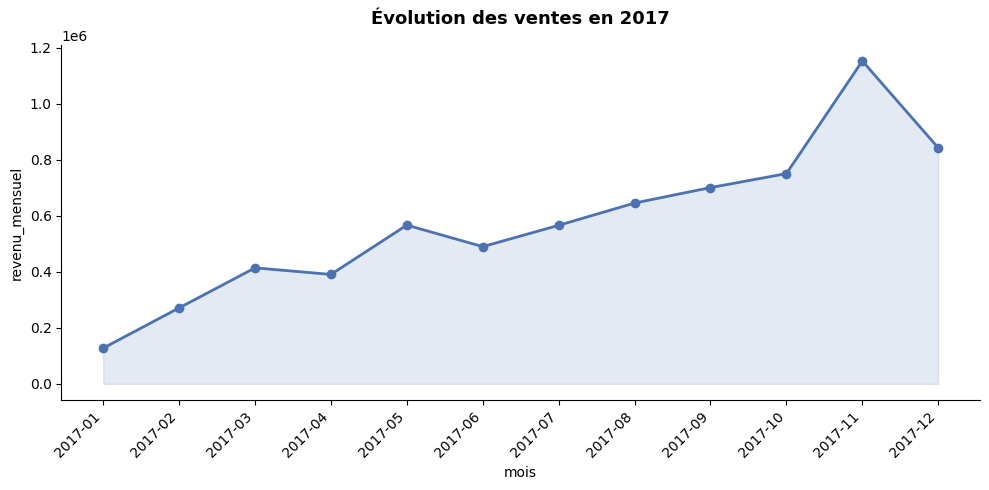

'\n# Mémoire conversationnelle\nprint("\n" + "=" * 60)\ntalk_to_assistant("Et en 2017 ?");\n\n# Hors périmètre\nprint("\n" + "=" * 60)\ntalk_to_assistant("Comment faire une pâte à crêpe ?");\n\n# Panier moyen par catégorie\nprint("\n" + "=" * 60)\ntalk_to_assistant("Quel est le panier moyen pour les produits de la catégorie beleza_saude ?");\n\n# évolution temporelle des revenus mensuelles\nprint("\n" + "=" * 60)\ntalk_to_assistant("Quels sont les revenus mensuels et leur évolution au fil du temps ?");\n\n# classement top N produits vendus en 2017\nprint("\n" + "=" * 60)\ntalk_to_assistant("Quels sont les 10 produits les plus vendus en volume en 2017 ?");\n\n# répartition des moyens de paiement\nprint("\n" + "=" * 60)\ntalk_to_assistant("Quelle est la répartition des moyens de paiement ?");\n\n#  évolution panier moyen\nprint("\n" + "=" * 60)\nresult=talk_to_assistant("Quel est le panier moyen par mois ?");\nprint(" SQL :", result["sql"])\n'

In [ ]:
print("=" * 60)
talk_to_assistant("Bonjour");


# Question classique
print("=" * 60)
talk_to_assistant("montre l'evolution des ventes en 2017");


### Autres exemples de questions
À exécuter une par une (mémoire conversationnelle, hors périmètre, top produits, paiements...).

In [ ]:
exemples = [
    "Et en 2018 ?",                                                        # mémoire conversationnelle
    "Comment faire une pâte à crêpe ?",                                    # hors périmètre
    "Quel est le panier moyen pour les produits de la catégorie beleza_saude ?",
    "Quels sont les revenus mensuels et leur évolution au fil du temps ?",
    "Quels sont les 10 produits les plus vendus en volume en 2017 ?",
    "Quelle est la répartition des moyens de paiement ?",
    "Quel est le panier moyen par mois ?",
]

# Décommenter pour tout lancer d'un coup (plan gratuit : peut prendre du temps)
# for q in exemples:
#     print("=" * 60)
#     talk_to_assistant(q)

print("=" * 60)
result = talk_to_assistant(exemples[-1])
print("SQL :", result["sql"])